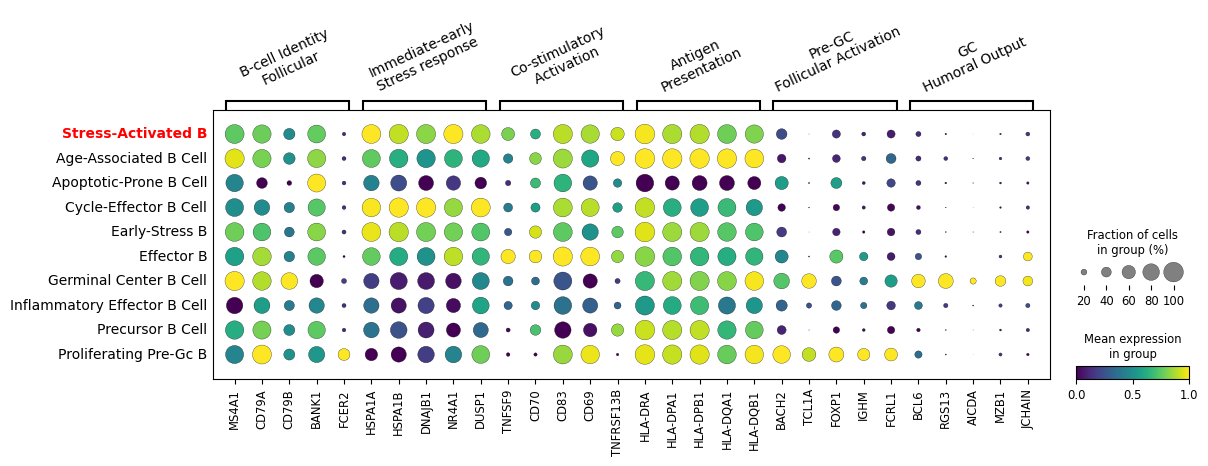

In [1]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np


gene_sets = {
    "B-cell Identity\nFollicular": ["MS4A1", "CD79A", "CD79B", "BANK1", "FCER2"],
    "Immediate-early\nStress response": ["HSPA1A", "HSPA1B", "DNAJB1", "NR4A1", "DUSP1"],
    "Co-stimulatory\n Activation": ["TNFSF9", "CD70", "CD83", "CD69", "TNFRSF13B"],
    "Antigen\nPresentation": ["HLA-DRA", "HLA-DPA1", "HLA-DPB1", "HLA-DQA1", "HLA-DQB1"],
    "Pre-GC\nFollicular Activation": ["BACH2", "TCL1A", "FOXP1", "IGHM", "FCRL1"],
    "GC\nHumoral Output": ["BCL6", "RGS13", "AICDA", "MZB1", "JCHAIN"]
}

adata_B = sc.read("../h5ad/adata_B.h5ad")
sc.pp.normalize_total(adata_B, target_sum=1e6)
sc.pp.log1p(adata_B)
# 1. Define the list of cell subtypes to be highlighted in red and placed at the top
highlight_subtypes = ['Stress-Activated B'] 

# 2. Ensure the categorical order in adata_B is correct (move highlighted subtypes to the top)
original_cats = adata_B.obs['celltype'].cat.categories.tolist()
remaining_cats = [ct for ct in original_cats if ct not in highlight_subtypes]
new_order = highlight_subtypes + remaining_cats
adata_B.obs['celltype'] = adata_B.obs['celltype'].cat.reorder_categories(new_order)

# 3. Plot
dotplot = sc.pl.dotplot(
    adata_B,
    var_names=gene_sets, 
    groupby='celltype',
    cmap='viridis',               
    standard_scale='var',         
    show=False,
    return_fig=True
)

# 4. Get the axes
axes_dict = dotplot.get_axes()
main_ax = axes_dict['mainplot_ax']  # Central heatmap
top_ax = axes_dict['gene_group_ax'] # Top gene names

# 5. Directly extract the sorted Y-axis label texts from adata
sorted_y_labels = adata_B.obs['celltype'].cat.categories.tolist()

# 6. Hide the automatically generated Y-axis tick labels from Matplotlib (to prevent overlap)
main_ax.set_yticks([]) 

# 7. Manually draw the labels on the left side of the heatmap
# Calculate Y coordinates for Y-axis labels (evenly distributed between 0 and N-1)
y_positions = np.arange(len(sorted_y_labels))

for i, label in enumerate(sorted_y_labels):
    # Determine whether to highlight in red and bold
    is_highlight = label in highlight_subtypes
    text_color = 'red' if is_highlight else 'black'
    font_weight = 'bold' if is_highlight else 'normal'
    
    # Manually add text to the left of main_ax
    # x = -0.5 leaves some space on the left side of the axis
    main_ax.text(
        -0.5, i+0.5, label, 
        ha='right', va='center', 
        color=text_color, 
        fontweight=font_weight, 
        fontsize=10,
        transform=main_ax.transData  # Use data coordinate system
    )

# 8. Rotate the top gene set names
for text in top_ax.texts:
    text.set_rotation(25)

# 9. Refresh and display
dotplot.fig.canvas.draw() 
plt.show()